In [2]:
df = pd.read_csv('train.csv', encoding='latin1')
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


In [3]:
df.shape

(9800, 18)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9800 non-null   int64  
 1   Order ID       9800 non-null   object 
 2   Order Date     9800 non-null   object 
 3   Ship Date      9800 non-null   object 
 4   Ship Mode      9800 non-null   object 
 5   Customer ID    9800 non-null   object 
 6   Customer Name  9800 non-null   object 
 7   Segment        9800 non-null   object 
 8   Country        9800 non-null   object 
 9   City           9800 non-null   object 
 10  State          9800 non-null   object 
 11  Postal Code    9789 non-null   float64
 12  Region         9800 non-null   object 
 13  Product ID     9800 non-null   object 
 14  Category       9800 non-null   object 
 15  Sub-Category   9800 non-null   object 
 16  Product Name   9800 non-null   object 
 17  Sales          9800 non-null   float64
dtypes: float

In [5]:
df.isnull().sum()

,0
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country,0
City,0


In [6]:
df.describe()

,Row ID,Postal Code,Sales
count,9800.000000,9789.000000,9800.000000
mean,4900.500000,55273.322403,230.769059
std,2829.160653,32041.223413,626.651875
min,1.000000,1040.000000,0.444000
25%,2450.750000,23223.000000,17.248000
50%,4900.500000,58103.000000,54.490000
75%,7350.250000,90008.000000,210.605000
max,9800.000000,99301.000000,22638.480000


In [8]:
df['Order Date'] = pd.to_datetime(df['Order Date'], dayfirst=True)
df['Order Date'].dtype

dtype('<M8[ns]')

In [9]:
df['Ship Date'] = pd.to_datetime(df['Ship Date'], dayfirst=True)
df['Ship Date'].dtype

dtype('<M8[ns]')

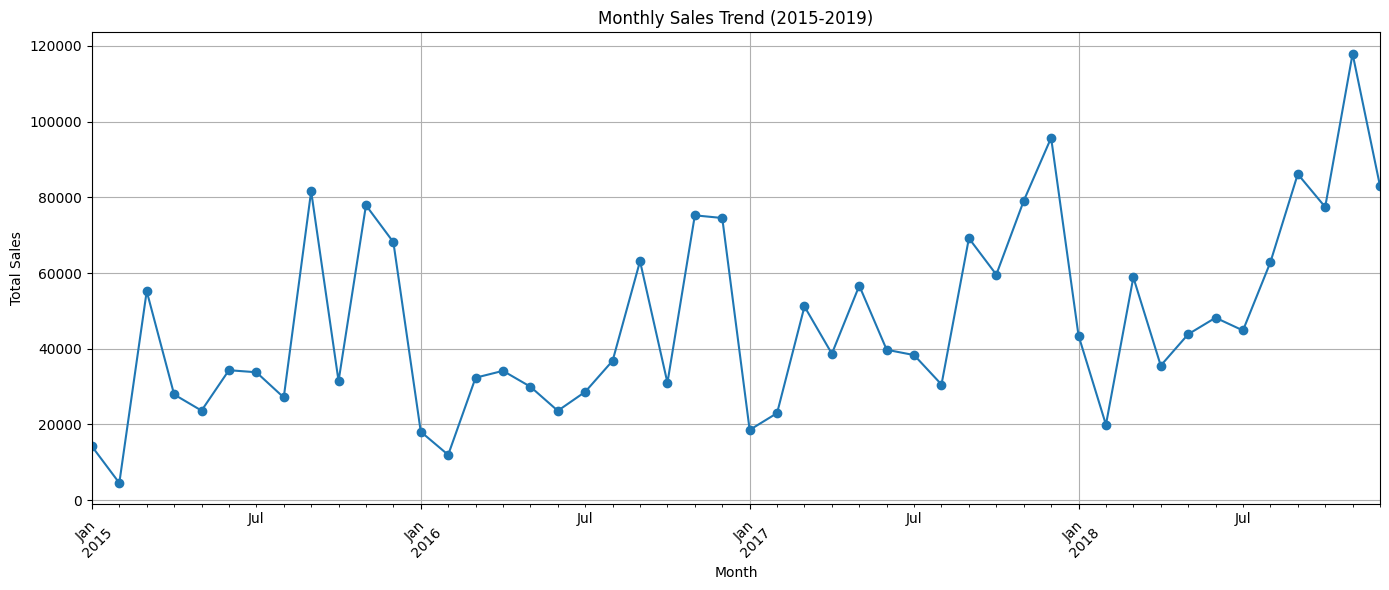

In [10]:
monthly_sales = df.groupby(df['Order Date'].dt.to_period('M'))['Sales'].sum()

plt.figure(figsize=(14,6))
monthly_sales.plot(kind='line', marker='o')
plt.title('Monthly Sales Trend (2015-2019)')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

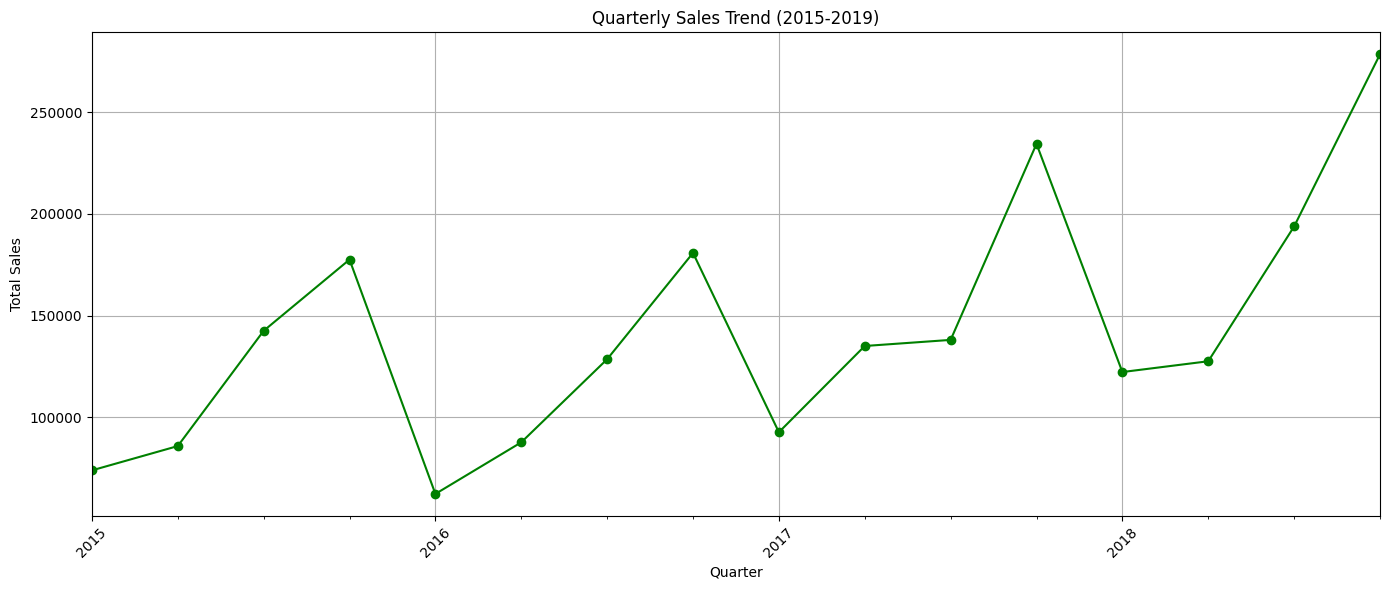

In [11]:
quarterly_sales = df.groupby(df['Order Date'].dt.to_period('Q'))['Sales'].sum()

plt.figure(figsize=(14,6))
quarterly_sales.plot(kind='line', marker='o', color='green')
plt.title('Quarterly Sales Trend (2015-2019)')
plt.xlabel('Quarter')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

## Time Series Analysis

The quarterly sales trend shows a clear, repeating seasonal pattern across all four years: sales consistently dip in Q1 (post-holiday slowdown) and build steadily through the year, peaking sharply in Q4. This likely reflects holiday season shopping behavior.

Beyond the seasonal pattern, there's also a clear year-over-year growth trend — each year's Q4 peak is higher than the previous year's, suggesting the business is growing overall, not just cycling seasonally.

In [12]:
df.columns.tolist()

['Row ID',
 'Order ID',
 'Order Date',
 'Ship Date',
 'Ship Mode',
 'Customer ID',
 'Customer Name',
 'Segment',
 'Country',
 'City',
 'State',
 'Postal Code',
 'Region',
 'Product ID',
 'Category',
 'Sub-Category',
 'Product Name',
 'Sales']

Segment
Consumer       1.148061e+06
Corporate      6.884941e+05
Home Office    4.249822e+05
Name: Sales, dtype: float64


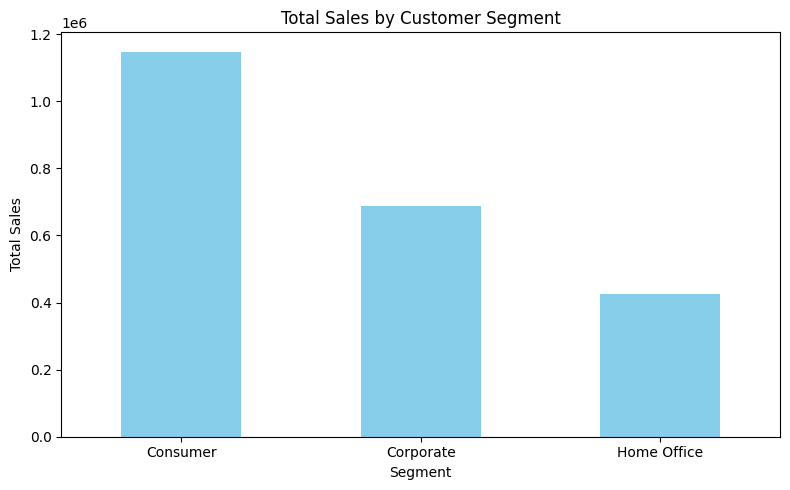

In [14]:
segment_sales = df.groupby('Segment')['Sales'].sum().sort_values(ascending=False)
print(segment_sales)

plt.figure(figsize=(8,5))
segment_sales.plot(kind='bar', color='skyblue')
plt.title('Total Sales by Customer Segment')
plt.xlabel('Segment')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

   ## Customer Segment Analysis

   The Consumer segment generates by far the most total sales (~$1.15M), more than Corporate (~$0.7M) and Home Office (~$0.45M) combined with room to spare. This suggests individual consumers are the core revenue driver for this business, and marketing/inventory decisions should weight Consumer behavior most heavily.

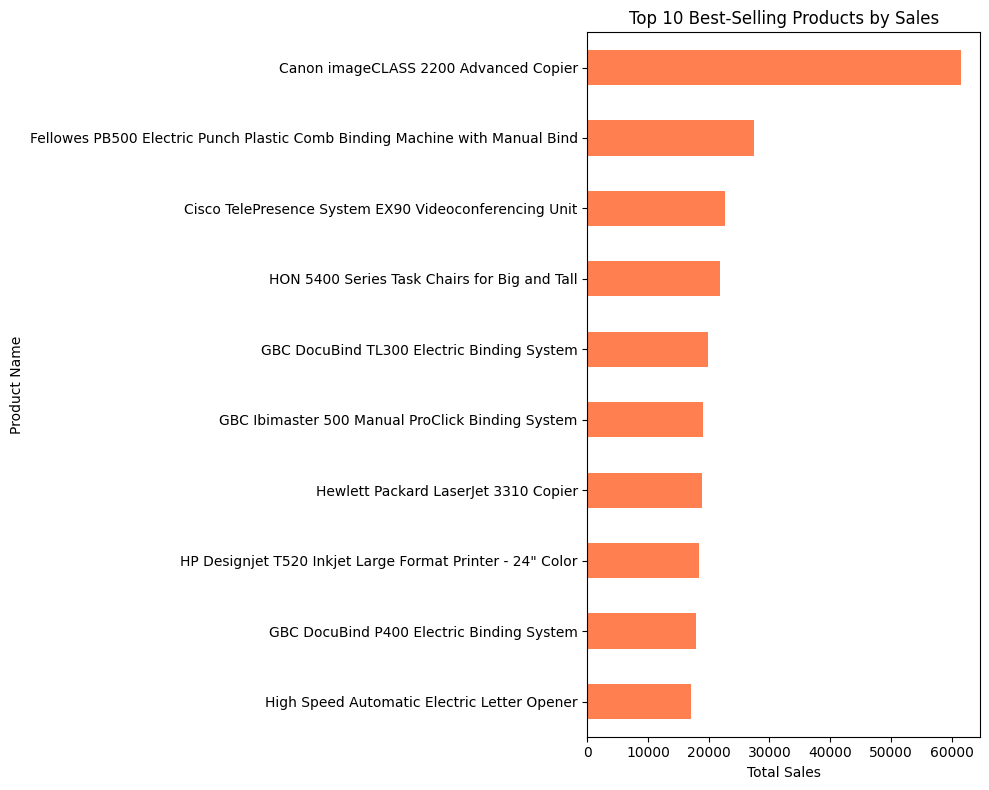

In [15]:
top_products = df.groupby('Product Name')['Sales'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(10,8))
top_products.plot(kind='barh', color='coral')
plt.title('Top 10 Best-Selling Products by Sales')
plt.xlabel('Total Sales')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

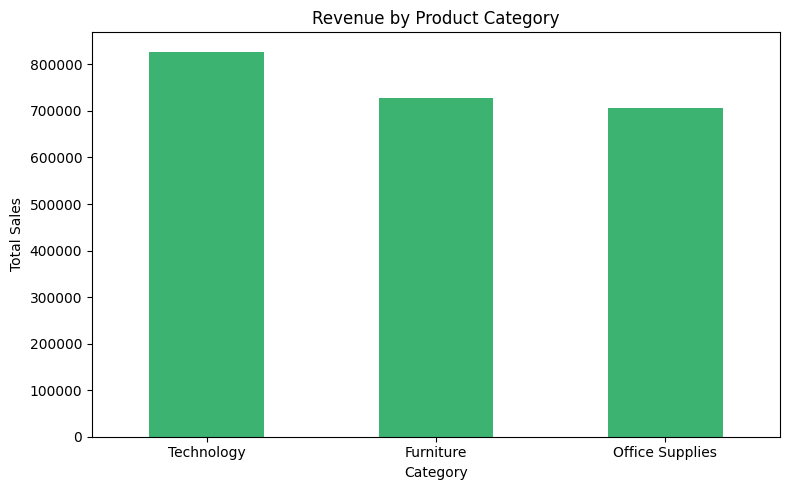

In [16]:
category_sales = df.groupby('Category')['Sales'].sum().sort_values(ascending=False)

plt.figure(figsize=(8,5))
category_sales.plot(kind='bar', color='mediumseagreen')
plt.title('Revenue by Product Category')
plt.xlabel('Category')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

   ## Top Products Analysis

   The Canon imageCLASS 2200 Advanced Copier is by far the best-selling product by revenue, notably ahead of the next closest items (binding machines, a Cisco videoconferencing unit, and task chairs). High-value office equipment items dominate the top of the list, rather than small everyday office supplies.

   ## Product Category Analysis

   Technology leads in revenue (~$830K), narrowly ahead of Furniture (~$740K) and Office Supplies (~$720K). Unlike the segment breakdown, category revenue is fairly balanced across all three — no single category dominates the business the way Consumer dominates by segment.

In [18]:
   df.columns.tolist()

['Row ID',
 'Order ID',
 'Order Date',
 'Ship Date',
 'Ship Mode',
 'Customer ID',
 'Customer Name',
 'Segment',
 'Country',
 'City',
 'State',
 'Postal Code',
 'Region',
 'Product ID',
 'Category',
 'Sub-Category',
 'Product Name',
 'Sales']

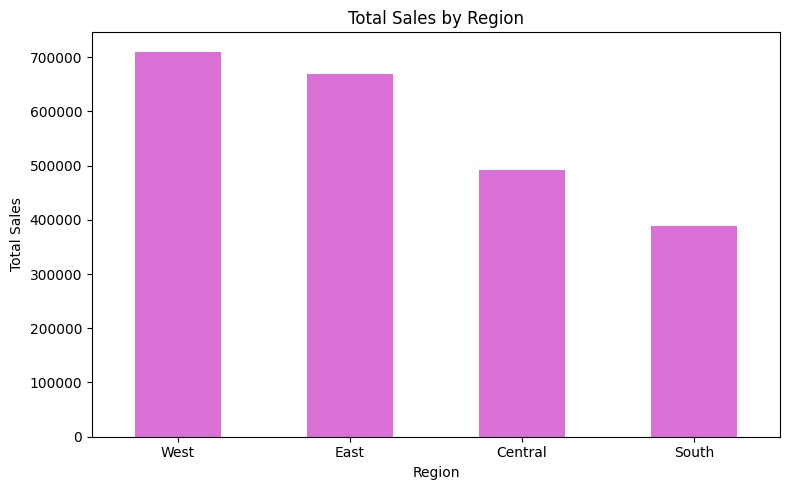

In [19]:
region_sales = df.groupby('Region')['Sales'].sum().sort_values(ascending=False)

plt.figure(figsize=(8,5))
region_sales.plot(kind='bar', color='orchid')
plt.title('Total Sales by Region')
plt.xlabel('Region')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Note on Correlation Heatmap

This version of the Superstore dataset does not include Quantity, Discount, or Profit columns — only Sales as a numeric variable, alongside categorical fields (Region, Category, Segment, etc.). A traditional correlation heatmap across multiple numeric variables isn't meaningful here. Instead, substituted a Region-wise sales breakdown as an additional insight-driven visualization.

## Regional Sales Analysis

West and East regions lead in sales (~$720K and ~$715K respectively), significantly outperforming Central (~$500K) and especially South (~$390K). This roughly 2x gap between the strongest and weakest regions suggests West and East may have denser customer bases, stronger market penetration, or more effective regional operations — worth investigating further for resource allocation.

## Conclusion & Business Recommendations

Based on this analysis of the Superstore dataset, three actionable recommendations:

1. **Double down on Q4 readiness.** Sales consistently peak in Q4 every year — ensure adequate inventory of top-selling products (like the Canon imageCLASS 2200 Advanced Copier) ahead of this period, and consider targeted Q4 marketing campaigns to maximize this natural demand spike.

2. **Investigate the South region's underperformance.** South generates roughly half the sales of West or East. A deeper investigation into local market conditions, store/distribution presence, or targeted marketing could help close this gap.

3. **Prioritize the Consumer segment in strategy.** Since Consumer sales (~$1.15M) far outpace Corporate and Home Office combined, customer experience, loyalty programs, and marketing spend should be weighted toward individual consumers rather than split evenly across all three segments.